# Diabetes Health Indicators : dépistage du diabète

Mini-projet Machine Learning, TAF MCE (IMT Atlantique).

On reprend ici le même workflow que pour Spambase, avec les fonctions de `ml_workflow.py`.

## 0. Le problème et le choix de la métrique

Chaque ligne correspond à un répondant de l'enquête téléphonique BRFSS 2015 (CDC). La cible `Diabetes_binary` vaut 1 en cas de diabète ou de prédiabète déclaré, et les 21 variables décrivent l'état de santé et le mode de vie (tension, cholestérol, IMC, âge, revenu...).

On voit le modèle comme un outil de dépistage : il doit repérer les personnes à orienter vers un test sanguin. Rater un diabétique coûte bien plus cher qu'un test inutile, donc on cherche avant tout un bon rappel, sans que la précision s'effondre.

Comme il n'y a que 14 % de positifs, l'accuracy n'est pas adaptée. On compare les modèles avec l'AUC-PR, plus parlante que l'AUC-ROC quand les positifs sont rares. Le seuil de décision est ensuite choisi avec le score F2, qui donne deux fois plus de poids au rappel qu'à la précision. On regarde aussi un seuil bayésien avec un coût $c_{FN} = 5\,c_{FP}$.

In [1]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import ml_workflow as mw

SEED = 42
pd.set_option("display.precision", 4)
pd.set_option("display.width", 160)
plt.rcParams["figure.dpi"] = 90

## 1. Import et contrôle des données

In [2]:
df = mw.load_diabetes("data/diabetes_binary_health_indicators_BRFSS2015.csv")
X, y = mw.split_features_target(df, "Diabetes_binary")
display(mw.describe_dataset(df, "Diabetes_binary"))
types = mw.variable_types(X)
print(types.value_counts().to_string())
print("\nOrdinales/discrètes :", list(types[types == "ordinale/discrète"].index))
print("Continues :", list(types[types == "continue"].index))

n_lignes                                  253680.0000
n_features                                    21.0000
valeurs_manquantes                             0.0000
lignes_dupliquees                          24206.0000
doublons_X_avec_labels_contradictoires      1566.0000
proportion_positifs                            0.1393
accuracy_classe_majoritaire                    0.8607
dtype: float64

binaire              14
ordinale/discrète     4
continue              3

Ordinales/discrètes : ['GenHlth', 'Age', 'Education', 'Income']
Continues : ['BMI', 'MentHlth', 'PhysHlth']


Pas de valeur manquante (les non-réponses ont déjà été retirées du jeu Kaggle), mais on garde l'imputation dans le pipeline par sécurité. Les variables ordinales (GenHlth, Age, Education, Income) sont laissées telles quelles : leur ordre a un sens qu'un encodage one-hot ferait perdre.

Le point plus délicat, ce sont les 24 206 doublons (9,5 % des lignes). Contrairement à Spambase, on les garde : avec 14 variables binaires et des ordinales assez grossières, deux personnes différentes peuvent très bien avoir le même profil. Les supprimer reviendrait à sous-représenter les profils les plus courants.

Part de positifs parmi les lignes dupliquées : 1.3%  |  parmi les autres : 16.0%
Profil le plus fréquent :


,0
Diabetes_binary,0
HighBP,0
HighChol,0
CholCheck,1
BMI,21
Smoker,0
Stroke,0
HeartDiseaseorAttack,0
PhysActivity,1
Fruits,1


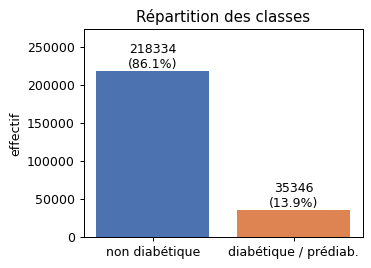

In [3]:
dup = df.duplicated(keep=False)
print(f"Part de positifs parmi les lignes dupliquées : {y[dup].mean():.1%}  |  parmi les autres : {y[~dup].mean():.1%}")
print("Profil le plus fréquent :")
display(df[df.duplicated(keep=False)].value_counts().head(1).reset_index().T)
mw.plot_class_balance(y, labels=("non diabétique", "diabétique / prédiab."));

Les doublons sont surtout des profils jeunes et sans facteur de risque, avec très peu de diabétiques. Ça confirme qu'il s'agit de personnes différentes au profil banal, et pas d'erreurs de saisie.

On note aussi que le classifieur « personne n'est diabétique » atteint déjà 86 % d'accuracy.

### Exploration rapide

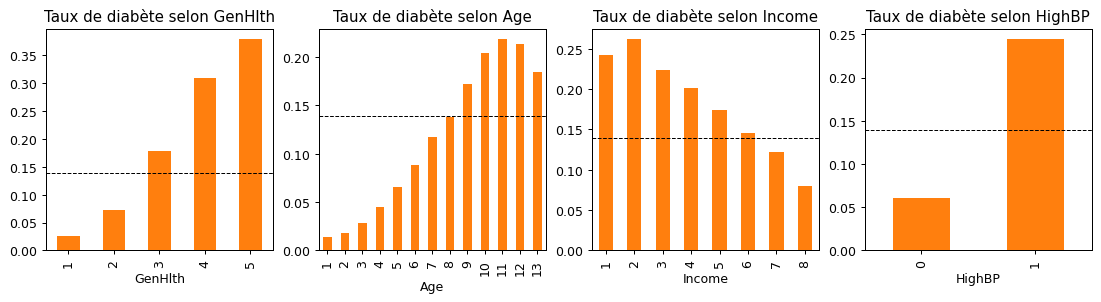

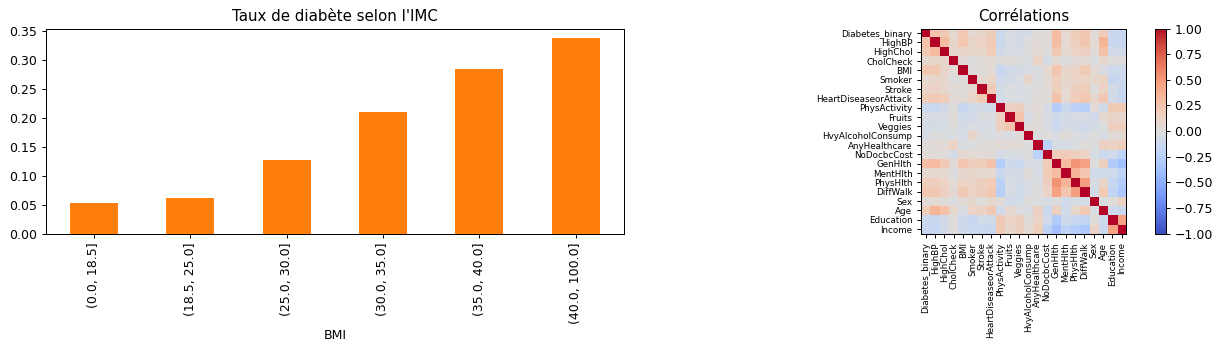

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.2))
for ax, col in zip(axes, ["GenHlth", "Age", "Income", "HighBP"]):
    y.groupby(X[col]).mean().plot.bar(ax=ax, color="C1")
    ax.axhline(y.mean(), color="k", ls="--", lw=0.8)
    ax.set_title(f"Taux de diabète selon {col}")
bmi_bins = pd.cut(X["BMI"], [0, 18.5, 25, 30, 35, 40, 100])
fig2, ax2 = plt.subplots(1, 2, figsize=(14, 4))
y.groupby(bmi_bins, observed=True).mean().plot.bar(ax=ax2[0], color="C1", title="Taux de diabète selon l'IMC")
corr = df.corr()
im = ax2[1].imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax2[1].set_xticks(range(len(corr)), corr.columns, rotation=90, fontsize=7)
ax2[1].set_yticks(range(len(corr)), corr.columns, fontsize=7)
plt.colorbar(im, ax=ax2[1]); ax2[1].set_title("Corrélations")
plt.tight_layout()

Les tendances sont nettes : le taux de diabète passe d'environ 2 % à près de 40 % selon la santé perçue, augmente avec l'âge et l'IMC, et baisse avec le revenu.

En revanche, aucune variable n'est fortement corrélée à la cible. Il manque des informations clés comme la glycémie, donc on ne s'attend pas à une séparation parfaite des classes.

## 2. Séparation train / test

Séparation stratifiée 80 / 20. Le test est mis de côté jusqu'à la section 8 : tous les choix se font par validation croisée sur le train.

In [5]:
X_train, X_test, y_train, y_test = mw.split_data(X, y, test_size=0.2, seed=SEED)
cv5, cv3 = mw.make_cv(5, SEED), mw.make_cv(3, SEED)
print(f"train : {X_train.shape}, {y_train.mean():.4f} de positifs | test : {X_test.shape}, {y_test.mean():.4f} de positifs")

SCORING = {
    "auc_pr": "average_precision",
    "auc_roc": "roc_auc",
    "acc_equilibree": "balanced_accuracy",
    "rappel": "recall",
    "precision": "precision",
    "f1": "f1",
}

train : (202944, 21), 0.1393 de positifs | test : (50736, 21), 0.1393 de positifs


## 3. Prétraitement

On centre et réduit les variables, ce qui est indispensable pour la régression logistique, le kNN, le SVM ou le MLP (l'IMC n'a pas du tout la même échelle que les variables binaires). Pas de transformation log ici : contrairement à Spambase, les distributions n'ont pas de queue lourde.

On regarde aussi ce que donne une ACP sur des variables en majorité binaires.

,PC1,PC2
GenHlth,0.4050,-0.0290
DiffWalk,0.3586,0.0160
PhysHlth,0.3440,-0.0762
Income,-0.3212,0.1904
Education,-0.2584,0.1495
HighBP,0.2565,0.3221
PhysActivity,-0.2371,0.0834
MentHlth,0.2232,-0.2527


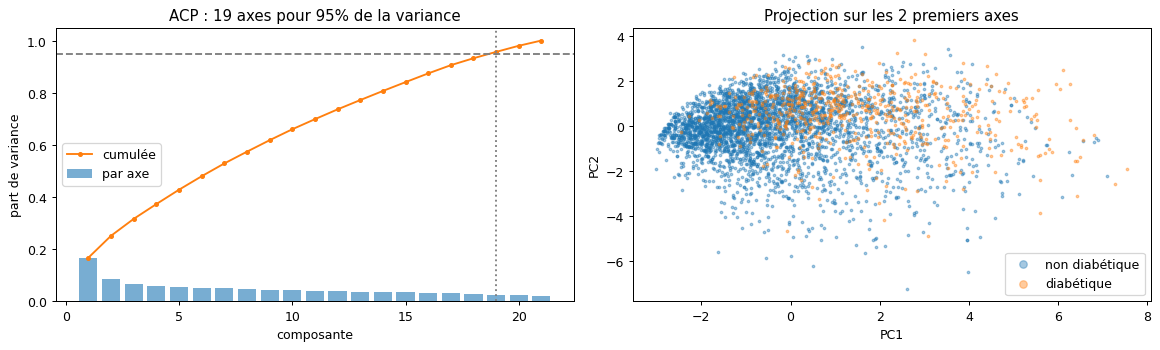

In [6]:
prep = mw.build_pipeline(None)                 # imputation -> centrage-réduction
Z_train = prep.fit_transform(X_train)
pca = mw.PCAManual(n_components=0.95).fit(Z_train)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
mw.plot_pca_variance(pca, 0.95, ax=axes[0])
mw.plot_pca_2d(pca.transform(Z_train), y_train, labels=("non diabétique", "diabétique"), ax=axes[1])
plt.tight_layout()
loadings = pd.DataFrame(pca.components_[:2].T, index=X.columns, columns=["PC1", "PC2"])
loadings.reindex(loadings["PC1"].abs().sort_values(ascending=False).index).head(8)

L'ACP ne compresse presque rien : il faut 19 axes sur 21 pour garder 95 % de la variance.

Le premier axe reste interprétable. Il oppose une mauvaise santé générale (GenHlth, DiffWalk, PhysHlth) à un niveau socio-économique élevé (Income, Education). Les diabétiques sont plutôt à droite, mais avec un fort recouvrement.

Il faut quand même rester prudent : pour une variable binaire, la variance $p(1-p)$ mesure surtout le déséquilibre entre 0 et 1, ce qui rend l'interprétation des axes plus fragile. L'effet de l'ACP sur la classification est mesuré en 6.3.

## 4. Comparaison des modèles

On reprend les modèles du notebook Spambase et on les compare par validation croisée 5 plis, sans traiter le déséquilibre pour l'instant (ce sera l'objet de la section 7). Le kNN et le SVM à noyau sont mis de côté pour des raisons de temps de calcul, qu'on vérifie juste après.

In [7]:
models = mw.get_models(SEED)
models["Random Forest"].set_params(n_estimators=150, min_samples_leaf=20)   # feuilles plus grosses : 200 000 lignes
names = ["Dummy (classe majoritaire)", "Régression logistique (GD, à la main)", "LDA (à la main)", "QDA (à la main)",
         "Bayes naïf gaussien", "Arbre de décision", "Random Forest", "Gradient Boosting (hist.)", "MLP (1 couche cachée)"]
res = mw.cross_validate_models({k: mw.build_pipeline(models[k]) for k in names}, X_train, y_train, SCORING, cv5)
res[["auc_pr_moy", "auc_pr_std", "auc_roc_moy", "acc_equilibree_moy", "rappel_moy", "precision_moy",
     "auc_pr_train", "temps_fit_s"]]

Dummy (classe majoritaire)                 auc_pr = 0.1393 ± 0.0000   (1.9 s)
Régression logistique (GD, à la main)      auc_pr = 0.4076 ± 0.0044   (2.0 s)
LDA (à la main)                            auc_pr = 0.4037 ± 0.0038   (1.7 s)
QDA (à la main)                            auc_pr = 0.3293 ± 0.0027   (1.5 s)
Bayes naïf gaussien                        auc_pr = 0.3419 ± 0.0022   (1.6 s)
Arbre de décision                          auc_pr = 0.4042 ± 0.0058   (1.7 s)
Random Forest                              auc_pr = 0.4316 ± 0.0064   (6.6 s)
Gradient Boosting (hist.)                  auc_pr = 0.4349 ± 0.0072   (3.5 s)
MLP (1 couche cachée)                      auc_pr = 0.4308 ± 0.0058   (4.2 s)


,auc_pr_moy,auc_pr_std,auc_roc_moy,acc_equilibree_moy,rappel_moy,precision_moy,auc_pr_train,temps_fit_s
modele,,,,,,,,
Gradient Boosting (hist.),0.4349,7.1790e-03,0.8301,0.5713,0.1609,0.5863,0.4597,2.0471
Random Forest,0.4316,6.3560e-03,0.8276,0.5509,0.1134,0.6104,0.5167,4.0985
MLP (1 couche cachée),0.4308,5.7881e-03,0.8292,0.5676,0.1531,0.5796,0.4402,2.3711
"Régression logistique (GD, à la main)",0.4076,4.3509e-03,0.8228,0.5681,0.1581,0.5389,0.4077,0.4846
Arbre de décision,0.4042,5.7779e-03,0.8172,0.5599,0.1377,0.5555,0.4226,0.3216
LDA (à la main),0.4037,3.8205e-03,0.8200,0.5876,0.2072,0.5121,0.4038,0.1542
Bayes naïf gaussien,0.3419,2.2043e-03,0.7848,0.6891,0.5720,0.3234,0.3419,0.1546
QDA (à la main),0.3293,2.7272e-03,0.7833,0.6715,0.5114,0.3296,0.3300,0.1511
Dummy (classe majoritaire),0.1393,1.1577e-05,0.5000,0.5000,0.0000,0.0000,0.1393,0.1580


Pour situer les scores, un classement au hasard donne une AUC-PR égale à la proportion de positifs, soit 0,139. Les meilleurs modèles la triplent (environ 0,43) : c'est utile, mais loin d'être parfait.

Gradient Boosting, Random Forest et MLP sont à égalité, avec des écarts inférieurs à un écart-type. La régression logistique et la LDA, toutes deux linéaires, sont environ 0,03 en dessous : les interactions apportent un gain réel mais modeste. QDA et Bayes naïf décrochent, car leurs hypothèses (covariance propre à chaque classe, indépendance) collent mal à des variables binaires corrélées.

Attention aux colonnes rappel et précision, calculées au seuil 0,5. Le boosting ne détecte que 16 % des diabétiques alors que c'est lui qui classe le mieux, et le meilleur rappel de QDA et du Bayes naïf vient seulement de probabilités mal calibrées. Le choix du seuil sera traité à part.

Enfin, la forêt sur-apprend nettement (AUC-PR de 0,52 en entraînement contre 0,43 en validation), alors que la régression logistique ne montre aucun écart.

### 4.1 Pourquoi pas de SVM à noyau ni de kNN ?

On mesure les temps d'entraînement et de prédiction sur des sous-échantillons de taille croissante.

In [8]:
expensive = {
    "SVM RBF": mw.build_pipeline(models["SVM RBF"]),
    "kNN": mw.build_pipeline(models["kNN"]),
    "Régression logistique (GD)": mw.build_pipeline(models["Régression logistique (GD, à la main)"]),
}
timing = mw.fit_time_scaling(expensive, X_train, y_train, sizes=[2500, 5000, 10000, 20000], seed=SEED)
display(timing.pivot(index="n_train", columns="modele", values=["fit_s", "predict_5000_s"]).round(3))

sub = np.random.default_rng(SEED).choice(len(X_train), 20000, replace=False)
res_sub = mw.cross_validate_models(
    {k: mw.build_pipeline(models[k]) for k in ["SVM RBF", "kNN", "Régression logistique (GD, à la main)", "Gradient Boosting (hist.)"]},
    X_train.iloc[sub], y_train.iloc[sub], {"auc_roc": "roc_auc", "acc_equilibree": "balanced_accuracy"}, cv3, verbose=False)
res_sub[["auc_roc_moy", "auc_roc_std", "temps_fit_s", "temps_predict_s"]]

fit_s                            predict_5000_s               
modele  Régression logistique (GD) SVM RBF    kNN Régression logistique (GD) SVM RBF    kNN
n_train                                                                                    
2500                         0.011   0.043  0.003                      0.001   0.119  0.018
5000                         0.018   0.147  0.005                      0.001   0.245  0.030
10000                        0.033   0.647  0.008                      0.001   0.401  0.038
20000                        0.052   2.657  0.017                      0.001   0.783  0.049

,auc_roc_moy,auc_roc_std,temps_fit_s,temps_predict_s
modele,,,,
"Régression logistique (GD, à la main)",0.8248,0.0068,0.0353,0.0051
Gradient Boosting (hist.),0.8219,0.0068,0.1505,0.0271
kNN,0.7778,0.0138,0.0124,0.3624
SVM RBF,0.7064,0.0083,1.2184,1.5288


Pour le SVM, passer de 10 000 à 20 000 lignes multiplie le temps d'entraînement par 4 environ : la croissance est quadratique. Sur 200 000 lignes, chaque entraînement prendrait plusieurs minutes, à multiplier par le nombre de plis et de combinaisons d'hyperparamètres. Et sur 20 000 lignes, il fait nettement moins bien que la régression logistique (AUC-ROC de 0,71 contre 0,82).

Le kNN s'entraîne instantanément mais prédit lentement. C'est surtout sa performance qui l'écarte (0,78) : une distance euclidienne entre des profils binaires et ordinaux n'a pas beaucoup de sens.

### 4.2 Biais ou variance ? Courbe d'apprentissage et courbe de validation

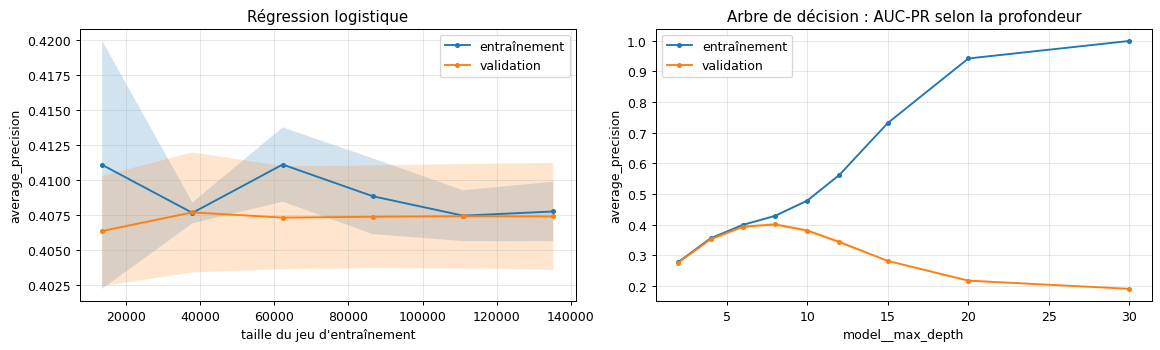

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
mw.plot_learning_curve(mw.build_pipeline(models["Régression logistique (GD, à la main)"]), X_train, y_train,
                       "average_precision", cv3, ax=axes[0], title="Régression logistique")
mw.plot_validation_curve(mw.build_pipeline(mw.clone(models["Arbre de décision"]).set_params(min_samples_leaf=1)),
                         X_train, y_train, "model__max_depth", [2, 4, 6, 8, 10, 12, 15, 20, 30],
                         "average_precision", cv3, ax=axes[1])
axes[1].set_title("Arbre de décision : AUC-PR selon la profondeur")
plt.tight_layout()

La régression logistique a des scores d'entraînement et de validation quasiment confondus, quelle que soit la taille du train. Elle est limitée par son biais : plus de données n'y changeraient rien, il faudrait un modèle plus riche.

L'arbre de décision montre le cas inverse. Au-delà d'une profondeur de 8, il continue de progresser sur le train mais s'effondre en validation (0,19 à profondeur 30), car il finit par isoler des individus. La profondeur 8 utilisée par défaut est donc bien placée.

## 5. Réglage des hyperparamètres

Grille sur $C$ pour la régression logistique, recherche aléatoire sur 12 combinaisons pour le Gradient Boosting. Avec 200 000 lignes, 3 plis suffisent.

In [10]:
best_lr, tab_lr = mw.tune_model(mw.build_pipeline(models["Régression logistique (GD, à la main)"]),
                                {"model__C": [1e-4, 1e-3, 1e-2, 1e-1, 1, 10]}, X_train, y_train, "average_precision", cv3)
display(tab_lr)
best_gb, tab_gb = mw.tune_model(mw.build_pipeline(models["Gradient Boosting (hist.)"]),
                                {"model__learning_rate": [0.03, 0.05, 0.1, 0.2],
                                 "model__max_leaf_nodes": [7, 15, 31, 63],
                                 "model__min_samples_leaf": [20, 100, 400],
                                 "model__l2_regularization": [0.0, 1.0, 10.0],
                                 "model__max_iter": [1000]},
                                X_train, y_train, "average_precision", cv3, n_iter=12, seed=SEED)
tab_gb.head(5)

,C,mean_test_score,std_test_score
0,0.0010,0.4079,0.0037
1,0.0100,0.4075,0.0038
2,0.1000,0.4074,0.0038
3,1.0000,0.4074,0.0038
4,10.0000,0.4074,0.0038
5,0.0001,0.4039,0.0033


,min_samples_leaf,max_leaf_nodes,max_iter,learning_rate,l2_regularization,mean_test_score,std_test_score
0,400,15,1000,0.05,1.0,0.4352,0.0080
1,400,31,1000,0.03,1.0,0.4351,0.0076
2,100,31,1000,0.05,0.0,0.4349,0.0073
3,20,63,1000,0.05,10.0,0.4348,0.0068
4,20,31,1000,0.05,0.0,0.4347,0.0074


Les deux modèles sont presque insensibles à leurs hyperparamètres. Pour la régression logistique, avec 200 000 lignes pour 21 coefficients, la pénalité n'a pas grand-chose à corriger. Pour le boosting, les 12 combinaisons tombent toutes entre 0,433 et 0,435.

Sur ce jeu, ce sont donc les données elles-mêmes qui limitent les performances, pas le réglage.

## 6. Sélection de variables

### 6.1 Classement par quatre critères

,anova_F,info_mutuelle,abs_coef_L1,permutation_RF,rang_moyen
GenHlth,2882.4402,0.0487,0.5697,0.0416,1.00
BMI,1586.6642,0.0266,0.4227,0.0415,2.50
HighBP,2170.4250,0.0378,0.3669,0.0233,2.75
HighChol,1165.0769,0.0190,0.2543,0.0097,5.00
Age,964.3748,0.0176,0.3739,0.0215,5.00
Income,913.8453,0.0143,0.1181,0.0023,7.75
HeartDiseaseorAttack,1044.7581,0.0103,0.0873,0.0040,8.00
DiffWalk,1426.3711,0.0189,0.0119,0.0028,8.50
Education,547.2121,0.0104,0.0547,0.0015,10.50
PhysHlth,909.4051,0.0106,0.0458,0.0015,10.50


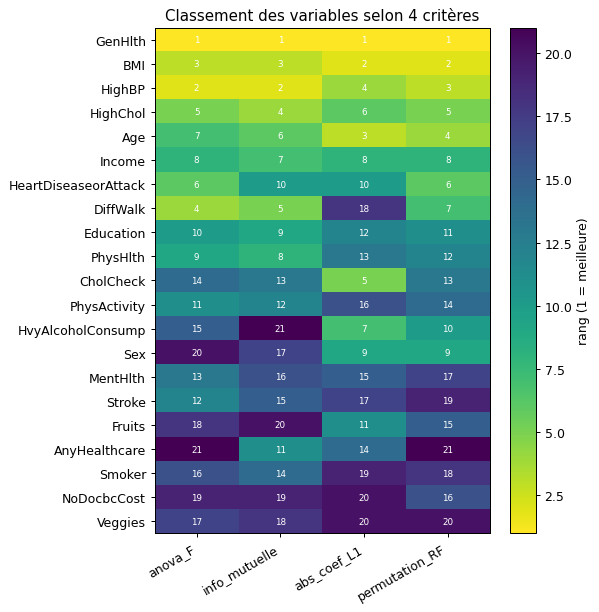

In [11]:
ranking = mw.rank_features(X_train, y_train, seed=SEED, n_perm_samples=30000)
mw.plot_feature_ranking(ranking, top=21)
ranking[["anova_F", "info_mutuelle", "abs_coef_L1", "permutation_RF", "rang_moyen"]].round(4)

Les quatre critères s'accordent sur les variables principales : GenHlth, BMI, HighBP, Age et HighChol, qui sont les facteurs de risque connus du diabète de type 2.

Les désaccords sont plus intéressants. DiffWalk est 4e pour l'ANOVA mais 18e pour la L1 : prise seule, elle est très liée au diabète, mais son information est redondante avec GenHlth et PhysHlth. À l'inverse, CholCheck, HvyAlcoholConsump ou Sex sont mal classées par les filtres et bien placées par la L1. Leur effet n'apparaît qu'à profil égal, ce qu'un critère univarié ne peut pas voir.

### 6.2 Score en fonction du nombre de variables, et wrapper RFE

RFECV (régression logistique) garde 18 variables ; écartées : ['Smoker', 'Veggies', 'NoDocbcCost']


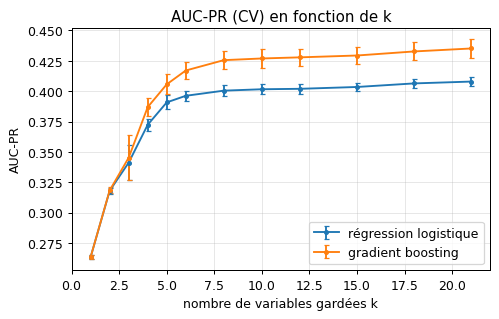

In [12]:
from sklearn.feature_selection import SelectKBest, f_classif, RFECV
from sklearn.linear_model import LogisticRegression
lr_model, gb_model = best_lr.named_steps["model"], best_gb.named_steps["model"]
ks = [1, 2, 3, 4, 5, 6, 8, 10, 12, 15, 18, 21]
curve_lr = mw.cv_score_vs_k(lambda k: mw.build_pipeline(lr_model, selector=SelectKBest(f_classif, k=k)),
                            X_train, y_train, ks, "average_precision", cv3)
curve_gb = mw.cv_score_vs_k(lambda k: mw.build_pipeline(gb_model, selector=SelectKBest(f_classif, k=k)),
                            X_train, y_train, ks, "average_precision", cv3)
ax = mw.plot_score_vs_k(curve_lr, "AUC-PR", label="régression logistique")
mw.plot_score_vs_k(curve_gb, "AUC-PR", ax=ax, label="gradient boosting")
ax.legend()

rfecv = RFECV(LogisticRegression(max_iter=2000), step=1, cv=cv3, scoring="average_precision", n_jobs=-1)
rfecv.fit(prep.fit_transform(X_train), y_train)       # exploratoire : on regarde quelles variables RFE garde
print(f"RFECV (régression logistique) garde {rfecv.n_features_} variables ; écartées :",
      list(X_train.columns[~rfecv.support_]))

L'AUC-PR plafonne à partir de 8 variables environ. Le RFECV, lui, écarte Smoker, Veggies et NoDocbcCost, qui étaient déjà en bas du classement précédent.

### 6.3 Toutes les variables, un sous-ensemble ou l'ACP ?

In [13]:
variants = {
    "LR — 21 variables": best_lr,
    "LR — 10 meilleures (ANOVA)": mw.build_pipeline(lr_model, selector=SelectKBest(f_classif, k=10)),
    "LR — RFECV": mw.build_pipeline(lr_model, selector=RFECV(LogisticRegression(max_iter=2000), step=1, cv=mw.make_cv(3, SEED),
                                                             scoring="average_precision")),
    "LR — ACP 95 %": mw.build_pipeline(lr_model, pca=0.95),
    "GB — 21 variables": best_gb,
    "GB — 10 meilleures (ANOVA)": mw.build_pipeline(gb_model, selector=SelectKBest(f_classif, k=10)),
    "GB — ACP 95 %": mw.build_pipeline(gb_model, pca=0.95),
}
res_sel = mw.cross_validate_models(variants, X_train, y_train, {"auc_pr": "average_precision", "auc_roc": "roc_auc"},
                                   cv3, verbose=False)
res_sel[["auc_pr_moy", "auc_pr_std", "auc_roc_moy", "temps_fit_s"]].sort_index()

,auc_pr_moy,auc_pr_std,auc_roc_moy,temps_fit_s
modele,,,,
GB — 10 meilleures (ANOVA),0.4269,0.0076,0.8258,1.7562
GB — 21 variables,0.4352,0.0080,0.8306,3.9771
GB — ACP 95 %,0.4211,0.0051,0.8236,1.6811
LR — 10 meilleures (ANOVA),0.4016,0.0042,0.8185,0.2432
LR — 21 variables,0.4079,0.0037,0.8227,0.3816
LR — ACP 95 %,0.4011,0.0036,0.8165,0.3530
LR — RFECV,0.4079,0.0037,0.8228,1.8878


Retirer les 3 variables écartées par RFECV ne change rien (0,4079 dans les deux cas), et ne garder que 10 variables coûte moins de 0,01 d'AUC-PR.

L'ACP, elle, fait perdre des points, surtout au boosting (0,435 → 0,421). Les arbres perdent les coupures naturelles sur les variables d'origine (« HighBP = 1 »), et l'ACP choisit ses axes selon la variance, sans regarder le lien avec la cible.

On garde les 21 variables pour le modèle final. Pour un vrai questionnaire de dépistage, la version à 10 variables serait un bon compromis : 11 questions de moins pour une perte minime.

## 7. Traitement du déséquilibre

On compare six stratégies sur la régression logistique et le Gradient Boosting réglés :
- aucun traitement (seuil 0,5) ;
- pondération des classes ;
- sous-échantillonnage de la classe majoritaire ;
- SMOTE ;
- seuil bayésien pour $c_{FN}/c_{FP}=5$, soit $\hat p > 1/6$ ;
- seuil qui maximise le F2, choisi par validation croisée interne.

Le rééchantillonnage n'est appliqué qu'aux plis d'entraînement.

In [14]:
SCORING_IMB = {"f2": mw.fbeta_scorer(2),
               "rappel": "recall", "precision": "precision", "acc_equilibree": "balanced_accuracy",
               "auc_pr": "average_precision", "auc_roc": "roc_auc"}
tables = {}
for label, base in [("Régression logistique", lr_model), ("Gradient Boosting", gb_model)]:
    strategies = mw.imbalance_strategies(base, beta=2, cost_fn=5, cost_fp=1, seed=SEED)
    t = mw.cross_validate_models(strategies, X_train, y_train, SCORING_IMB, cv3, verbose=False)
    tables[label] = t[[f"{m}_moy" for m in SCORING_IMB] + ["temps_fit_s"]]
    print(label); display(tables[label])

Régression logistique


,f2_moy,rappel_moy,precision_moy,acc_equilibree_moy,auc_pr_moy,auc_roc_moy,temps_fit_s
modele,,,,,,,
seuil max F2 (CV interne),0.5999,0.8341,0.2827,0.7457,0.4079,0.8227,1.9655
sous-échantillonnage,0.5927,0.7630,0.3132,0.7461,0.4069,0.8230,0.1850
class_weight='balanced',0.5927,0.7648,0.3119,0.7458,0.4064,0.8233,0.3492
SMOTE,0.5917,0.7617,0.3126,0.7453,0.4044,0.8226,1.3954
seuil bayésien (c_FN/c_FP=5 → 0.167),0.5795,0.7108,0.3333,0.7403,0.4079,0.8227,0.3824
"aucun traitement (seuil 0,5)",0.1656,0.1410,0.5465,0.5610,0.4079,0.8227,0.3746


Gradient Boosting


,f2_moy,rappel_moy,precision_moy,acc_equilibree_moy,auc_pr_moy,auc_roc_moy,temps_fit_s
modele,,,,,,,
seuil max F2 (CV interne),0.6055,0.8284,0.2917,0.7513,0.4352,0.8306,12.2381
class_weight='balanced',0.6023,0.7932,0.3069,0.7516,0.4344,0.8305,3.7293
sous-échantillonnage,0.6021,0.7953,0.3053,0.7512,0.4308,0.8294,0.8405
seuil bayésien (c_FN/c_FP=5 → 0.167),0.5920,0.7372,0.3312,0.7481,0.4352,0.8306,4.0936
SMOTE,0.2212,0.1921,0.5626,0.5840,0.4327,0.8284,23.5995
"aucun traitement (seuil 0,5)",0.1945,0.1668,0.5812,0.5737,0.4352,0.8306,3.9504


Sans traitement, le modèle ne détecte que 14 à 17 % des diabétiques. Il répond presque toujours « sain », ce qui minimise l'erreur totale quand 86 % des gens le sont.

Pondération, sous-échantillonnage et changement de seuil donnent des résultats très proches. Ce n'est pas un hasard : pondérer les positifs par $w$ revient à peu près à décaler le logit de $\log w$, c'est-à-dire à déplacer le seuil. Le classement des individus ne change pas, et les AUC restent les mêmes.

Le meilleur F2 est obtenu en choisissant directement le seuil qui le maximise. Le seuil bayésien est un peu plus prudent (rappel de 71 à 74 %, précision de 33 %).

Reste un résultat étonnant : SMOTE fonctionne avec la régression logistique, mais échoue complètement avec le boosting (19 % de rappel).

In [15]:
from imblearn.over_sampling import SMOTE
auc_syn = mw.synthetic_vs_real_auc(X_train, y_train, SMOTE(random_state=SEED), seed=SEED)
print(f"AUC d'un classifieur qui distingue vrais diabétiques et diabétiques synthétiques de SMOTE : {auc_syn:.3f}")

AUC d'un classifieur qui distingue vrais diabétiques et diabétiques synthétiques de SMOTE : 0.998


Les diabétiques créés par SMOTE sont presque parfaitement reconnaissables. SMOTE interpole entre deux diabétiques voisins, ce qui produit des valeurs impossibles pour des variables binaires ou entières (HighBP = 0,37, Age = 8,6...).

Le boosting, très flexible, apprend donc qu'une valeur non entière signifie « diabétique ». Mais aucun vrai patient n'a de valeur non entière, et le modèle ne reconnaît plus les diabétiques du test. La régression logistique, linéaire, ne peut pas exploiter cet artefact.

## 8. Modèle final, seuil, puis évaluation sur le test

### 8.1 Calibration des probabilités

Le seuil bayésien n'a de sens que si les probabilités prédites sont fiables. On le vérifie sur les scores hors pli du train.

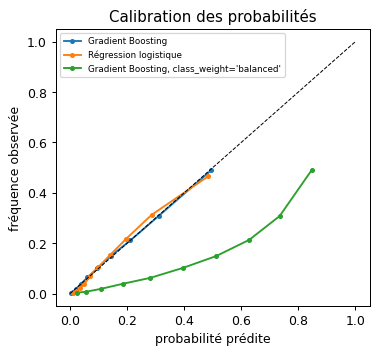

In [16]:
oof_gb = mw.out_of_fold_scores(best_gb, X_train, y_train, cv3)
oof_lr = mw.out_of_fold_scores(best_lr, X_train, y_train, cv3)
gb_bal = mw.clone(best_gb).set_params(model__class_weight="balanced")
oof_gb_bal = mw.out_of_fold_scores(gb_bal, X_train, y_train, cv3)
mw.plot_calibration({"Gradient Boosting": oof_gb, "Régression logistique": oof_lr,
                     "Gradient Boosting, class_weight='balanced'": oof_gb_bal}, y_train);

Sans pondération, le boosting et la régression logistique sont bien calibrés : le seuil $\hat p > 1/6$ a donc bien le sens voulu.

Avec `class_weight='balanced'`, les probabilités sont fortement surestimées, puisque le modèle a appris sur une population fictive à 50 % de diabétiques. C'est une raison de plus pour garder le modèle non pondéré et agir sur le seuil : on conserve un score interprétable comme un risque.

Modèle retenu : Gradient Boosting
Seuil max F2 (hors pli, train) : 0.118 | seuil bayésien (c_FN = 5 c_FP) : 0.167


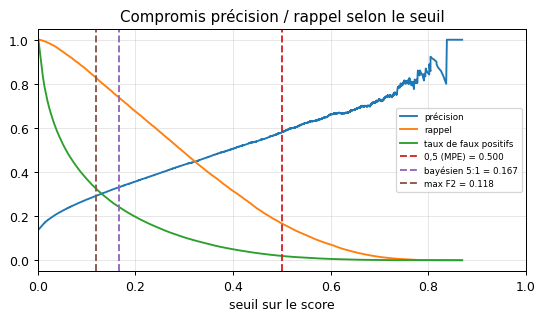

In [17]:
# choix par validation croisée (section 5) : meilleure AUC-PR moyenne
FINAL_NAME = "Gradient Boosting" if tab_gb.loc[0, "mean_test_score"] > tab_lr.loc[0, "mean_test_score"] else "Régression logistique"
print("Modèle retenu :", FINAL_NAME)
final_model = best_gb if FINAL_NAME == "Gradient Boosting" else best_lr
oof = oof_gb if FINAL_NAME == "Gradient Boosting" else oof_lr
thr_f2 = mw.fbeta_threshold(y_train, oof, beta=2)
thr_bayes = mw.bayes_risk_threshold(cost_fn=5, cost_fp=1)
print(f"Seuil max F2 (hors pli, train) : {thr_f2:.3f} | seuil bayésien (c_FN = 5 c_FP) : {thr_bayes:.3f}")
mw.plot_threshold_tradeoff(y_train, oof, {"0,5 (MPE)": 0.5, "bayésien 5:1": thr_bayes, "max F2": thr_f2});

### 8.2 Évaluation finale (le test n'est utilisé qu'ici)

,auc_pr,auc_roc,accuracy,accuracy_equilibree,rappel,precision,specificite,f2,VP,FN,FP
"seuil 0,5 = 0.500",0.4234,0.8272,0.8652,0.5707,0.1624,0.5557,0.9790,0.1892,1148.0,5921.0,918.0
seuil bayésien = 0.167,0.4234,0.8272,0.7567,0.7488,0.7379,0.3321,0.7598,0.5930,5216.0,1853.0,10490.0
seuil F2 = 0.118,0.4234,0.8272,0.6934,0.7512,0.8312,0.2903,0.6711,0.6056,5876.0,1193.0,14362.0


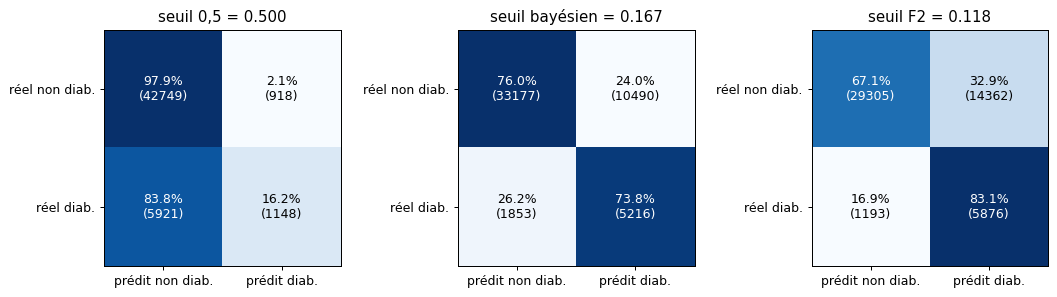

In [18]:
final_model.fit(X_train, y_train)
results = {f"seuil {name} = {t:.3f}": mw.evaluate_on_test(final_model, X_test, y_test, threshold=t, beta=2)
           for name, t in [("0,5", 0.5), ("bayésien", thr_bayes), ("F2", thr_f2)]}
cols = ["auc_pr", "auc_roc", "accuracy", "accuracy_equilibree", "rappel", "precision", "specificite", "f2", "VP", "FN", "FP"]
display(mw.results_table(results, cols))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
for ax, (name, m) in zip(axes, results.items()):
    mw.plot_confusion(m, ("non diab.", "diab."), normalize=True, ax=ax, title=name)
plt.tight_layout()

Au seuil 0,5, l'accuracy (86,5 %) est à peine meilleure que celle du classifieur trivial, avec seulement 16 % des diabétiques détectés.

Avec le seuil F2 (0,118, choisi sur le train), le modèle détecte 83 % des diabétiques. Parmi les personnes signalées, 29 % sont réellement diabétiques, contre 14 % dans la population : le dépistage devient deux fois plus ciblé. En contrepartie, un tiers des personnes saines sont envoyées vers un test.

Le seuil bayésien se situe entre les deux (74 % de rappel, 24 % de faux positifs).

Enfin, les AUC sur le test (0,423 et 0,827) restent proches de celles de la validation croisée, ce qui montre que nos choix n'ont pas sur-appris le train.

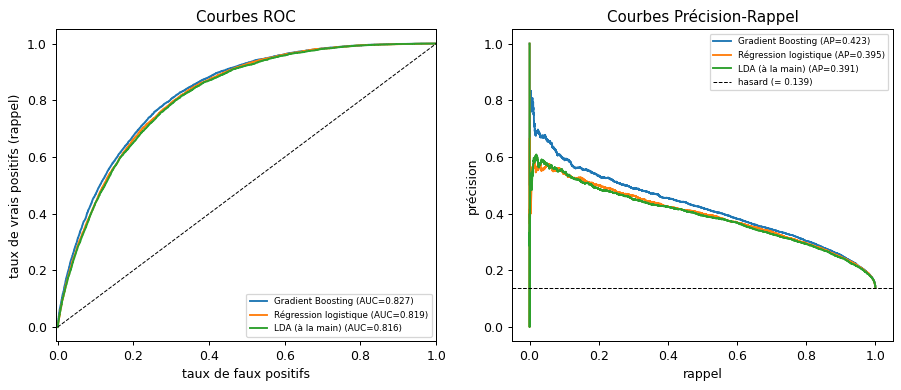

In [19]:
final_lr = mw.clone(best_lr).fit(X_train, y_train)
lda_pipe = mw.build_pipeline(mw.GaussianBayesClassifier("shared", reg=1e-3)).fit(X_train, y_train)
scores = {"Gradient Boosting": mw.get_scores(best_gb.fit(X_train, y_train), X_test),
          "Régression logistique": mw.get_scores(final_lr, X_test),
          "LDA (à la main)": mw.get_scores(lda_pipe, X_test)}
mw.plot_roc_pr(scores, y_test);

Ces courbes n'ont servi à aucun choix, elles situent simplement le modèle retenu par rapport aux deux suivants.

## 9. Conclusion

Le modèle retenu est un Gradient Boosting sur les 21 variables, sans pondération des classes, avec un seuil de 0,118 choisi pour maximiser le F2. Sur le test, il détecte 83 % des diabétiques avec une précision de 29 %, pour une AUC-PR de 0,42 (contre 0,14 pour le hasard).

Il obtient la meilleure AUC-PR en validation croisée, à égalité avec la forêt et le MLP, tout en sur-apprenant moins que la forêt. Ne pas pondérer les classes permet de garder des probabilités calibrées, et le seuil peut ensuite être ajusté selon l'usage.

La régression logistique reste une alternative sérieuse. Elle est un peu moins performante (0,03 d'AUC-PR en moins), mais plus rapide, bien calibrée et directement interprétable, ce qui compte dans un contexte médical.

Ce qu'on retient surtout de ce jeu :
- la vraie difficulté est le déséquilibre, qui oblige à bien choisir la métrique et le seuil ;
- pondération, sous-échantillonnage et changement de seuil reviennent quasiment au même ;
- ni le réglage des hyperparamètres ni l'ACP n'apportent quelque chose, les performances sont limitées par les données ;
- SMOTE est risqué avec des variables discrètes.

Il faut garder en tête que les données sont déclaratives, que la cible mélange diabète et prédiabète, et que le rapport de coûts 5:1 est une hypothèse qu'un médecin devrait fixer. Le modèle sert à prioriser un dépistage, pas à poser un diagnostic.

Le `README.md` compare les conclusions obtenues sur les deux jeux.